# 05 · Exploración de algoritmos de agrupamiento

**Entrada:** matrices del notebook 04 (`data/processed/matrices/`).

Este notebook responde dos preguntas:

1. **¿Qué 3 algoritmos se incluyen en la metodología?** Se prueban 7 algoritmos de 5 familias distintas y se eligen 3 con criterios explícitos y reproducibles.
2. **¿Qué hacer con los delitos poco frecuentes?** Se evalúa si los tres delitos sexuales agravados deben mantenerse por separado, **agruparse** o **excluirse**.

| Familia | Algoritmos | Idea |
|---|---|---|
| Particional (centroides) | **K-means**, **K-medoids** | Cada municipio pertenece al grupo con el centro más cercano. |
| Jerárquica | **Ward**, **BIRCH** | Une municipios paso a paso según su similitud (árbol o dendrograma). |
| Probabilística | **Mezcla gaussiana (GMM)** | Cada grupo es una distribución normal; la asignación es una probabilidad. |
| Basada en grafos | **Spectral clustering** | Agrupa usando una red de vecinos cercanos. |
| Basada en densidad | **DBSCAN**, **HDBSCAN** | Los grupos son zonas densas; los municipios aislados se marcan como ruido. |

## 0. Configuración

In [1]:
import sys
import json
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import (KMeans, AgglomerativeClustering, Birch, SpectralClustering,
                             DBSCAN, HDBSCAN)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

from src.utilidades import (RUTA_PROCESSED, RAIZ as RAIZ_PROY, CODIGO_A_CORTO, COLOR,
                            PALETA_CATEGORICA, configurar_estilo, subtitulo, fuente,
                            guardar_figura)
from src.modelos import KMedoids, metricas_internas, estabilidad_bootstrap

# SpectralClustering avisa cuando el grafo de vecinos no es totalmente conexo; no afecta el resultado.
warnings.filterwarnings("ignore", category=UserWarning)

configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CARPETA_FIG = "05_exploracion"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
SEMILLA = 42
RANGO_K = range(2, 9)          # rango explorado
K_EVALUACION = [3, 4, 5, 6]    # rango para puntuar (ver sección 3)
K_ESTABILIDAD = [3, 4, 5]
N_BOOT = 30
RUTA_REPORTES = RAIZ_PROY / "outputs" / "reports"
RUTA_REPORTES.mkdir(parents=True, exist_ok=True)

def cargar(nombre):
    return pd.read_csv(RUTA_PROCESSED / "matrices" / f"{nombre}.csv", index_col=0, encoding="utf-8-sig")

X1 = cargar("R1_log_suavizada_standard")
print(f"Representación principal R1: {X1.shape[0]} municipios × {X1.shape[1]} variables")

Representación principal R1: 340 municipios × 12 variables


## 1. Métricas de evaluación

Como no hay etiquetas verdaderas, se usan **métricas internas**, que miden cohesión (qué tan parecidos son los municipios de un mismo grupo) y separación (qué tan distintos son los grupos entre sí):

| Métrica | Rango | Mejor | Qué mide |
|---|---|---|---|
| **Silhouette** | −1 a 1 | ↑ | Para cada municipio compara la distancia media a su grupo con la del grupo vecino más cercano. |
| **Davies-Bouldin** | ≥ 0 | ↓ | Similitud promedio entre cada grupo y su grupo más parecido (dispersión interna / separación). |
| **Calinski-Harabasz** | ≥ 0 | ↑ | Razón entre la varianza entre grupos y la varianza dentro de los grupos. |
| **Estabilidad (ARI bootstrap)** | ≈ 0 a 1 | ↑ | Qué tanto se repite la partición al remuestrear los municipios (Hennig, 2007). |

Además se revisa el **balance**: un resultado con un grupo que contiene al 90 % de los municipios no sirve para caracterizar territorios.

## 2. Algoritmos basados en densidad: DBSCAN y HDBSCAN

Se evalúan primero porque funcionan distinto: no reciben el número de grupos $k$, sino parámetros de densidad.

Para DBSCAN, `min_samples` = 2 × dimensiones = 24 (regla de Sander et al., 1998), y `eps` se explora alrededor del "codo" del gráfico de distancias al *k*-ésimo vecino.

,algoritmo,parámetro,k,pct_ruido,silhouette,pct_grupo_mayor
0,DBSCAN,eps = 1.5,0,100.00,NaN,100.00
1,DBSCAN,eps = 2.0,0,100.00,NaN,100.00
2,DBSCAN,eps = 2.5,1,21.47,NaN,100.00
3,DBSCAN,eps = 3.0,1,1.76,NaN,100.00
4,DBSCAN,eps = 3.5,1,0.00,NaN,100.00
5,DBSCAN,eps = 4.0,1,0.00,NaN,100.00
6,HDBSCAN,min_cluster_size = 5,3,69.41,0.24,22.35
7,HDBSCAN,min_cluster_size = 10,0,100.00,NaN,100.00
8,HDBSCAN,min_cluster_size = 15,0,100.00,NaN,100.00
9,HDBSCAN,min_cluster_size = 20,0,100.00,NaN,100.00


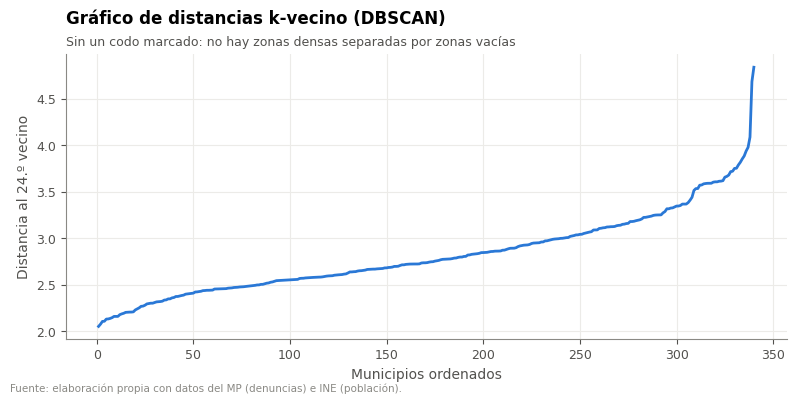

In [2]:
dist_k = np.sort(NearestNeighbors(n_neighbors=24).fit(X1).kneighbors(X1)[0][:, -1])

filas = []
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    m = metricas_internas(X1, DBSCAN(eps=eps, min_samples=24).fit_predict(X1))
    filas.append({"algoritmo": "DBSCAN", "parámetro": f"eps = {eps}", **m})
for mcs in [5, 10, 15, 20, 30]:
    m = metricas_internas(X1, HDBSCAN(min_cluster_size=mcs, copy=True).fit_predict(X1))
    filas.append({"algoritmo": "HDBSCAN", "parámetro": f"min_cluster_size = {mcs}", **m})
densidad = pd.DataFrame(filas)
display(densidad[["algoritmo", "parámetro", "k", "pct_ruido", "silhouette", "pct_grupo_mayor"]])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(dist_k) + 1), dist_k, color=COLOR["azul"])
ax.set_xlabel("Municipios ordenados")
ax.set_ylabel("Distancia al 24.º vecino")
ax.set_title("Gráfico de distancias k-vecino (DBSCAN)")
subtitulo(ax, "Sin un codo marcado: no hay zonas densas separadas por zonas vacías")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "01_dbscan_k_distancia", CARPETA_FIG)
plt.show()

**Resultado:** ninguna configuración produce una partición útil. DBSCAN encuentra **un solo grupo** o marca a casi todos los municipios como ruido. HDBSCAN, en su mejor caso, deja **más del 69 % como ruido**. La curva de distancias crece de forma suave y sin un codo claro, lo que confirma que los municipios **no forman zonas densas separadas**. Los algoritmos de densidad **se descartan con evidencia**.

## 3. Algoritmos que reciben el número de grupos $k$

Se prueban con $k = 2, \dots, 8$. Para puntuar se usa el rango **$k = 3$ a $6$**:

- $k = 2$ solo separa municipios de "alta" y "baja" incidencia, lo que es poco útil para caracterizar perfiles delictivos.
- Con más de 6 grupos, varios quedarían con muy pocos municipios, lo que dificulta la caracterización y la lectura del mapa.

El $k$ definitivo se elige en el notebook 06 con un análisis más amplio.

### 3.1 Variantes del GMM

El GMM tiene un hiperparámetro estructural, el **tipo de covarianza**: `full` (cada grupo con su propia matriz completa), `tied` (una matriz compartida), `diag` (solo varianzas) y `spherical` (una sola varianza). Se revisa el criterio de información bayesiano (**BIC**, menor es mejor).

,full,tied,diag,spherical
1,"9,455.00","9,455.00","11,718.00","11,654.00"
2,"9,625.00","9,484.00","10,358.00","10,513.00"
3,"9,849.00","9,454.00","9,837.00","10,126.00"
4,"10,158.00","9,460.00","9,727.00","10,081.00"
5,"10,551.00","9,460.00","9,715.00","10,031.00"
6,"10,906.00","9,483.00","9,765.00","10,006.00"
7,"11,281.00","9,521.00","9,835.00","10,008.00"
8,"11,685.00","9,566.00","9,884.00","10,017.00"


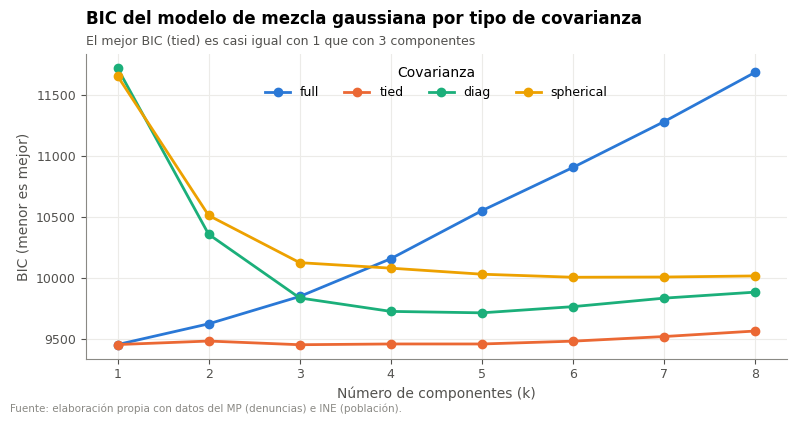

In [3]:
bic = pd.DataFrame({
    tipo: [GaussianMixture(k, covariance_type=tipo, n_init=5, random_state=SEMILLA,
                           reg_covar=1e-4).fit(X1).bic(X1) for k in range(1, 9)]
    for tipo in ["full", "tied", "diag", "spherical"]
}, index=range(1, 9))
display(bic.round(0))

fig, ax = plt.subplots(figsize=(8, 4.2))
for tipo, color in zip(bic.columns, PALETA_CATEGORICA):
    ax.plot(bic.index, bic[tipo], marker="o", color=color, label=tipo)
ax.set_xlabel("Número de componentes (k)")
ax.set_ylabel("BIC (menor es mejor)")
ax.set_title("BIC del modelo de mezcla gaussiana por tipo de covarianza")
subtitulo(ax, "El mejor BIC (tied) es casi igual con 1 que con 3 componentes")
ax.legend(title="Covarianza", ncol=4, loc="upper center")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "02_gmm_bic", CARPETA_FIG)
plt.show()

**Hallazgo relevante para la discusión:** el mejor BIC (`tied`) casi no mejora al pasar de 1 a 3 componentes. Visto como una distribución, el conjunto de municipios se parece más a **un continuo** (una nube alargada y correlacionada) que a grupos naturales bien separados. Esto coincide con el Hopkins moderado (0.70) del notebook 03. En consecuencia, el agrupamiento debe entenderse como una **segmentación útil de un continuo de incidencia**, y la elección del algoritmo y de $k$ debe apoyarse en la **estabilidad** y la **interpretabilidad**, no solo en una métrica.

`full` estima 90 parámetros por grupo con solo 340 municipios, lo que lleva a sobreajuste; por eso su BIC empeora con $k$. En el barrido se comparan las tres variantes no esféricas y se conserva la mejor.

In [4]:
def constructores(k):
    """Cada algoritmo como función X -> etiquetas, con semilla fija."""
    return {
        "K-means": lambda Z: KMeans(k, n_init=20, random_state=SEMILLA).fit_predict(Z),
        "K-medoids": lambda Z: KMedoids(k).fit(Z).labels_,
        "Ward": lambda Z: AgglomerativeClustering(k, linkage="ward").fit_predict(Z),
        "BIRCH": lambda Z: Birch(n_clusters=k, threshold=0.5).fit_predict(Z),
        "GMM (diag)": lambda Z: GaussianMixture(k, covariance_type="diag", n_init=5,
                                                random_state=SEMILLA).fit_predict(Z),
        "GMM (tied)": lambda Z: GaussianMixture(k, covariance_type="tied", n_init=5,
                                                random_state=SEMILLA).fit_predict(Z),
        "GMM (full)": lambda Z: GaussianMixture(k, covariance_type="full", n_init=5,
                                                random_state=SEMILLA, reg_covar=1e-3).fit_predict(Z),
        "Spectral": lambda Z: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=10,
                                                 random_state=SEMILLA).fit_predict(Z),
    }

FAMILIA = {"K-means": "Particional", "K-medoids": "Particional", "Ward": "Jerárquica",
           "BIRCH": "Jerárquica", "GMM (diag)": "Probabilística", "GMM (tied)": "Probabilística",
           "GMM (full)": "Probabilística", "Spectral": "Grafos"}

def barrido(X, algoritmos=None, rango_k=RANGO_K, k_estab=K_ESTABILIDAD, n_boot=N_BOOT):
    filas = []
    Xv = np.asarray(X)
    for k in rango_k:
        for nombre, ajustar in constructores(k).items():
            if algoritmos and nombre not in algoritmos:
                continue
            fila = {"algoritmo": nombre, "familia": FAMILIA[nombre],
                    **metricas_internas(Xv, ajustar(Xv))}
            fila["k"] = k
            if k in k_estab:
                fila["estabilidad"], fila["estabilidad_sd"] = estabilidad_bootstrap(
                    ajustar, Xv, n_boot=n_boot, semilla=SEMILLA)
            filas.append(fila)
    return pd.DataFrame(filas)

resultados = barrido(X1)
resultados.to_csv(RUTA_REPORTES / "05_barrido_algoritmos_R1.csv", index=False, encoding="utf-8-sig")
tabla = resultados.pivot_table(index="algoritmo", columns="k", values="silhouette")
print("Silhouette por algoritmo y k")
display(tabla)

Silhouette por algoritmo y k


k,2,3,4,5,6,7,8
algoritmo,,,,,,,
BIRCH,0.22,0.17,0.14,0.11,0.07,0.08,0.08
GMM (diag),0.26,0.19,0.13,0.13,0.12,0.11,0.08
GMM (full),0.20,0.11,0.09,0.09,0.08,0.08,0.07
GMM (tied),0.23,0.16,0.14,0.09,0.10,0.09,0.08
K-means,0.26,0.20,0.17,0.14,0.13,0.12,0.12
K-medoids,0.25,0.16,0.13,0.12,0.10,0.10,0.10
Spectral,0.27,0.20,0.15,0.13,0.12,0.11,0.11
Ward,0.22,0.17,0.09,0.08,0.07,0.07,0.07


### 3.2 Métricas en función de $k$

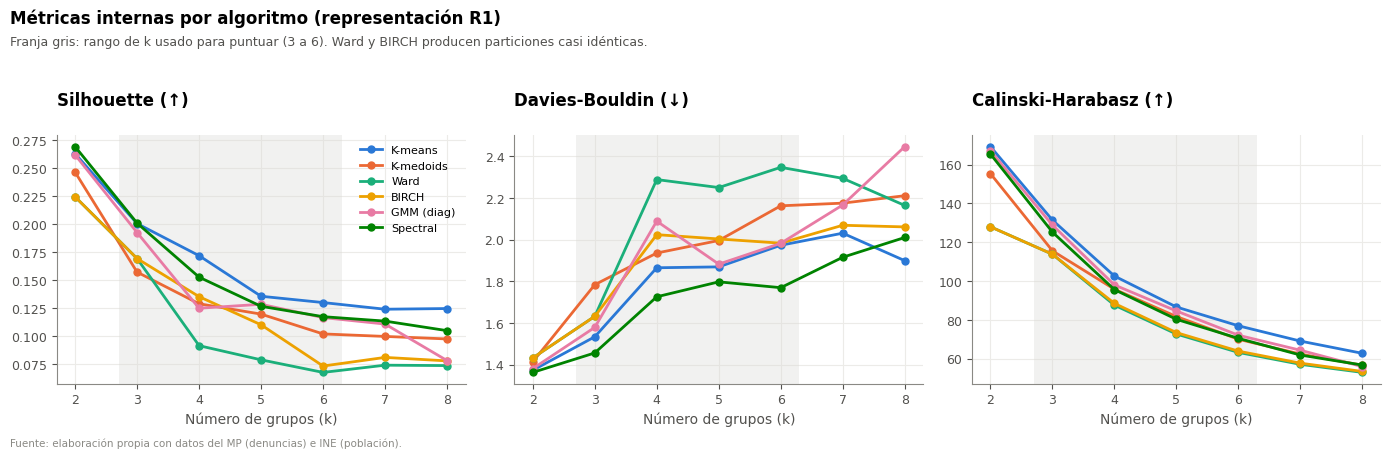

In [5]:
ALG_GRAF = ["K-means", "K-medoids", "Ward", "BIRCH", "GMM (diag)", "Spectral"]
COLOR_ALG = dict(zip(ALG_GRAF, PALETA_CATEGORICA))
metricas = [("silhouette", "Silhouette (↑)"), ("davies_bouldin", "Davies-Bouldin (↓)"),
            ("calinski_harabasz", "Calinski-Harabasz (↑)")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (col, titulo) in zip(axes, metricas):
    ax.axvspan(K_EVALUACION[0] - 0.3, K_EVALUACION[-1] + 0.3, color=COLOR["gris_claro"], alpha=0.35, lw=0)
    for alg in ALG_GRAF:
        d = resultados[resultados["algoritmo"] == alg]
        ax.plot(d["k"], d[col], marker="o", markersize=5, color=COLOR_ALG[alg], label=alg)
    ax.set_xlabel("Número de grupos (k)")
    ax.set_title(titulo)
    ax.set_xticks(list(RANGO_K))
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Métricas internas por algoritmo (representación R1)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, 0.9, "Franja gris: rango de k usado para puntuar (3 a 6). Ward y BIRCH producen "
         "particiones casi idénticas.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
guardar_figura(fig, "03_metricas_por_k", CARPETA_FIG)
plt.show()

Todas las métricas empeoran de forma gradual al aumentar $k$, sin un "codo" evidente. Esto es coherente con un continuo de incidencia. Los valores de Silhouette (0.1–0.27) indican una **estructura débil a moderada**, habitual en datos socioterritoriales. Por eso importa tanto la estabilidad.

### 3.3 Estabilidad

k,3,4,5,Promedio
algoritmo,,,,
Ward,0.49,0.40,0.37,0.42
GMM (full),0.47,0.36,0.43,0.42
BIRCH,0.50,0.41,0.38,0.43
GMM (tied),0.72,0.55,0.46,0.58
Spectral,0.87,0.68,0.51,0.68
K-medoids,0.73,0.70,0.64,0.69
K-means,0.91,0.61,0.63,0.71
GMM (diag),0.87,0.81,0.78,0.82


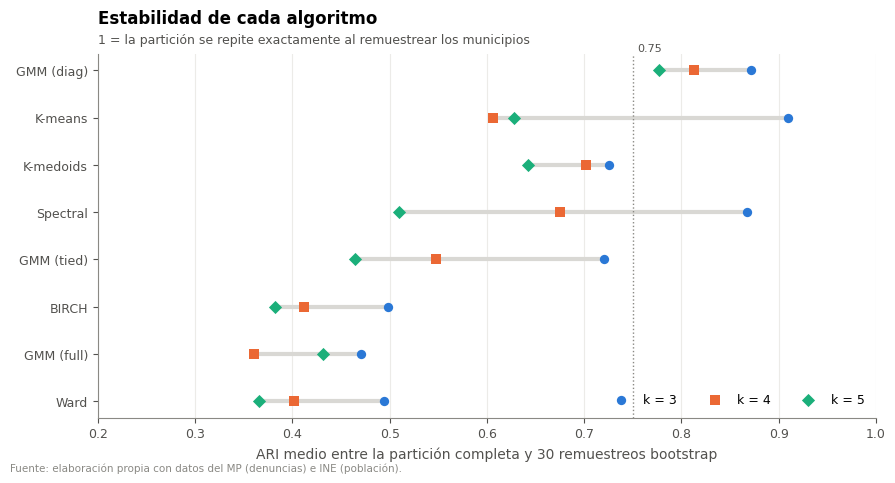

In [6]:
estab = resultados.dropna(subset=["estabilidad"]).pivot_table(index="algoritmo", columns="k",
                                                               values="estabilidad")
estab["Promedio"] = estab.mean(axis=1)
estab = estab.sort_values("Promedio")
display(estab)

fig, ax = plt.subplots(figsize=(9, 4.8))
marcadores = {3: "o", 4: "s", 5: "D"}
for i, alg in enumerate(estab.index):
    ax.plot([estab.loc[alg, K_ESTABILIDAD].min(), estab.loc[alg, K_ESTABILIDAD].max()], [i, i],
            color=COLOR["gris_claro"], linewidth=3, zorder=1)
    for k in K_ESTABILIDAD:
        ax.scatter(estab.loc[alg, k], i, marker=marcadores[k], s=45, zorder=2,
                   color=PALETA_CATEGORICA[k - 3], label=f"k = {k}" if i == 0 else None)
ax.axvline(0.75, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.text(0.755, len(estab) - 0.6, "0.75", fontsize=8, color=COLOR["texto_sec"])
ax.set_yticks(range(len(estab)), estab.index)
ax.set_xlim(0.2, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ARI medio entre la partición completa y 30 remuestreos bootstrap")
ax.set_title("Estabilidad de cada algoritmo")
subtitulo(ax, "1 = la partición se repite exactamente al remuestrear los municipios")
ax.legend(loc="lower right", ncol=3)
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "04_estabilidad_algoritmos", CARPETA_FIG)
plt.show()

## 4. Selección de los 3 algoritmos

### 4.1 Criterios

Los criterios se hacen **explícitos** para que la selección sea transparente y reproducible: cualquiera puede recalcular el ranking con el código. Se apoyan en la literatura (estabilidad de Hennig, métricas internas estándar) y en el objetivo del estudio (grupos útiles para caracterizar territorios):

1. **Calidad:** promedio de Silhouette, Davies-Bouldin y Calinski-Harabasz en $k = 3$ a $6$ (se ordena por cada métrica y se promedian las posiciones).
2. **Estabilidad:** ARI bootstrap promedio en $k = 3$ a $5$.
3. **Balance:** proporción de configuraciones ($k = 3$ a $6$) en las que el grupo más pequeño tiene al menos el 5 % de los municipios (17).
4. **Diversidad metodológica:** se elige **un algoritmo por familia**, para que la comparación de la metodología cubra enfoques realmente distintos.

La puntuación final es el **promedio de las posiciones** en los tres primeros criterios (1 = mejor).

In [7]:
def puntuar(res):
    ev = res[res["k"].isin(K_EVALUACION)]
    agg = ev.groupby("algoritmo").agg(
        familia=("familia", "first"),
        silhouette=("silhouette", "mean"),
        davies_bouldin=("davies_bouldin", "mean"),
        calinski_harabasz=("calinski_harabasz", "mean"),
        balance=("n_grupo_menor", lambda s: (s >= 17).mean()),
    )
    agg["estabilidad"] = res.dropna(subset=["estabilidad"]).groupby("algoritmo")["estabilidad"].mean()
    agg["pos_calidad"] = (agg["silhouette"].rank(ascending=False)
                          + agg["davies_bouldin"].rank(ascending=True)
                          + agg["calinski_harabasz"].rank(ascending=False)) / 3
    agg["pos_estabilidad"] = agg["estabilidad"].rank(ascending=False)
    agg["pos_balance"] = agg["balance"].rank(ascending=False)
    agg["puntuacion"] = agg[["pos_calidad", "pos_estabilidad", "pos_balance"]].mean(axis=1)
    return agg.sort_values("puntuacion")

ranking = puntuar(resultados)
display(ranking.round(3))

mejor_por_familia = ranking.reset_index().groupby("familia").first().sort_values("puntuacion")
display(mejor_por_familia[["algoritmo", "puntuacion", "silhouette", "estabilidad", "balance"]].round(3))
SELECCIONADOS = mejor_por_familia["algoritmo"].head(3).tolist()
print("Algoritmos seleccionados:", SELECCIONADOS)

,familia,silhouette,davies_bouldin,calinski_harabasz,balance,estabilidad,pos_calidad,pos_estabilidad,pos_balance,puntuacion
algoritmo,,,,,,,,,,
K-means,Particional,0.16,1.81,99.37,1.00,0.71,1.33,2.00,4.00,2.44
GMM (diag),Probabilística,0.14,1.88,95.86,1.00,0.82,2.67,1.00,4.00,2.56
K-medoids,Particional,0.13,1.97,90.75,1.00,0.69,4.67,3.00,4.00,3.89
Spectral,Grafos,0.15,1.69,92.86,0.75,0.68,2.00,4.00,8.00,4.67
GMM (tied),Probabilística,0.12,1.95,77.64,1.00,0.58,5.67,5.00,4.00,4.89
BIRCH,Jerárquica,0.12,1.91,84.87,1.00,0.43,5.00,6.00,4.00,5.00
Ward,Jerárquica,0.10,2.13,84.30,1.00,0.42,6.67,8.00,4.00,6.22
GMM (full),Probabilística,0.09,2.21,73.27,1.00,0.42,8.00,7.00,4.00,6.33


,algoritmo,puntuacion,silhouette,estabilidad,balance
familia,,,,,
Particional,K-means,2.44,0.16,0.71,1.00
Probabilística,GMM (diag),2.56,0.14,0.82,1.00
Grafos,Spectral,4.67,0.15,0.68,0.75
Jerárquica,BIRCH,5.00,0.12,0.43,1.00


Algoritmos seleccionados: ['K-means', 'GMM (diag)', 'Spectral']


### 4.2 Lectura del resultado

- **K-means** (particional) obtiene la mejor calidad promedio y una estabilidad alta, sobre todo con $k = 3$ (0.91).
- **GMM con covarianza diagonal** (probabilístico) es el **más estable** del conjunto (0.82 en promedio) y además da la probabilidad de pertenencia de cada municipio, útil para identificar municipios "de frontera".
- **Spectral** (grafos) tiene muy buen Davies-Bouldin y buena estabilidad en $k = 3$. Con $k = 6$ deja un grupo pequeño (12 municipios), lo que le resta en balance.
- **K-medoids** es el tercero del ranking general, pero pertenece a la misma familia que K-means, así que el criterio de diversidad lo deja fuera de la comparación principal. Sus ventajas (robustez a atípicos y un municipio real como centro) lo convierten en un **candidato natural para la etapa de optimización** si K-means resulta ganador.
- **Ward y BIRCH** (jerárquicos) producen particiones casi idénticas entre sí y son los **menos estables** (ARI ≈ 0.42): pequeñas variaciones en los datos cambian mucho el árbol.

## 5. Delitos poco frecuentes: ¿mantener, agrupar o excluir?

Se comparan cuatro representaciones (construidas en el notebook 04 con el mismo procesamiento):

| Código | Variables | Tratamiento de los 3 delitos sexuales agravados |
|---|---|---|
| **R1** | 12 | Por separado (referencia) |
| **R4a** | 9 | Sumados a su tipo penal: *violación total* y *agresión sexual total* |
| **R4b** | 10 | Sumados entre sí: *delitos sexuales agravados* |
| **R5** | 9 | Excluidos |

**Criterio de decisión.** Se hace explícito para que la elección sea transparente y reproducible. Prioriza, en este orden, conservar la estructura de los grupos, la estabilidad y la fidelidad al protocolo de 12 delitos:

1. Una alternativa **mejora** si, en promedio para los 3 algoritmos y $k = 3$ a $5$: sube la Silhouette al menos **0.02**, **no baja** la estabilidad más de 0.02 y **conserva la estructura** de R1 (ARI con la partición de R1 ≥ 0.80).
2. Entre las alternativas que mejoran, se prefiere la que **conserva la información de los 12 delitos** (R4a o R4b) sobre la que la descarta (R5). Si hay empate, la de mayor ARI con R1.
3. Si ninguna mejora, se mantiene **R1**, que es la más fiel al protocolo.

> **Nota de transparencia:** los umbrales (0.02 de Silhouette, 0.02 de estabilidad y 0.80 de ARI) se fijaron durante el análisis exploratorio. Por eso la tabla de la sección 5.2 muestra **todas** las alternativas con sus métricas: el lector puede aplicar otro criterio y ver si la conclusión cambia.

> **Nota:** comparar la Silhouette entre representaciones con distinto número de variables tiene una limitación: quitar variables ruidosas tiende a subirla. Por eso la regla exige además estabilidad y conservación de la estructura.

### 5.1 Influencia de cada delito en la partición actual (R1)

**Importancia por permutación:** se desordena aleatoriamente una variable, se reasigna cada municipio al grupo más cercano con el modelo ya ajustado y se mide el **% de municipios que cambian de grupo**. Una variable influyente provoca muchos cambios. Se aplica a los algoritmos seleccionados que pueden asignar municipios nuevos (K-means y GMM).

algoritmo                GMM (diag)               K-means              
k                                 3      4      5       3      4      5
delito                                                                 
Agresión sexual               8.000  7.900  7.200   6.800  5.900 10.400
Agresión sexual agrav.        2.300  2.900  4.400   3.900  7.400 10.200
Asesinato                     6.800  6.500 11.100   6.900 10.500 12.600
Extorsión                    10.200 15.900 17.500   6.300  9.200 13.100
Homicidio                     6.500  7.300 14.000   4.400 11.400 15.200
Hurto                         8.200 10.400 11.000   7.000  8.200 11.700
Hurto agravado               12.400 20.100 19.200   7.500  6.400 11.300
Robo                          6.100  7.300  8.200   6.400  7.700 10.200
Robo agravado                10.800 19.800 16.000   6.600  7.800 11.900
Violación                     2.500  2.000  3.100   3.700 11.800 13.300
Violación agravada            1.900  3.200  3.200   3.600  3.700  5.600
Violación c. esp. agrav.      1.700  1.900  2.000   2.400  4.600  6.100

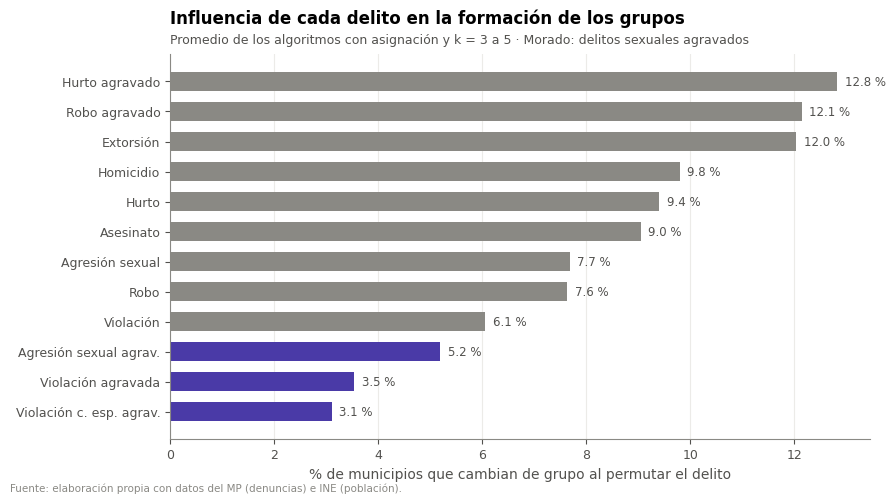

In [8]:
RAROS = ["violacion_agravada", "violacion_circ_especiales", "agresion_sexual_agravada"]
rng = np.random.default_rng(SEMILLA)
modelos_predict = {
    "K-means": lambda k: KMeans(k, n_init=20, random_state=SEMILLA),
    "K-medoids": lambda k: KMedoids(k),
    "GMM (diag)": lambda k: GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEMILLA),
}
importancias = []
for nombre in [a for a in SELECCIONADOS if a in modelos_predict]:
    for k in K_ESTABILIDAD:
        modelo = modelos_predict[nombre](k).fit(X1.values)
        base_lab = modelo.predict(X1.values)
        for j, col in enumerate(X1.columns):
            cambios = []
            for _ in range(30):
                Xp = X1.values.copy()
                Xp[:, j] = rng.permutation(Xp[:, j])
                cambios.append((modelo.predict(Xp) != base_lab).mean() * 100)
            importancias.append({"algoritmo": nombre, "k": k, "delito": col, "cambio_pct": np.mean(cambios)})
importancias = pd.DataFrame(importancias)
imp = importancias.groupby("delito")["cambio_pct"].mean().sort_values()
display(importancias.pivot_table(index="delito", columns=["algoritmo", "k"], values="cambio_pct")
        .rename(index=CODIGO_A_CORTO).round(1))

fig, ax = plt.subplots(figsize=(9, 5))
colores = [COLOR["violeta"] if d in RAROS else COLOR["gris"] for d in imp.index]
ax.barh([CODIGO_A_CORTO[d] for d in imp.index], imp.values, color=colores, height=0.65)
for i, v in enumerate(imp.values):
    ax.text(v + 0.15, i, f"{v:.1f} %", va="center", fontsize=8.5, color=COLOR["texto_sec"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de municipios que cambian de grupo al permutar el delito")
ax.set_title("Influencia de cada delito en la formación de los grupos")
subtitulo(ax, "Promedio de los algoritmos con asignación y k = 3 a 5 · Morado: delitos sexuales agravados")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "05_importancia_permutacion", CARPETA_FIG)
plt.show()

### 5.2 Comparación de representaciones

In [9]:
REPRESENTACIONES = {
    "R1 (12, separados)": "R1_log_suavizada_standard",
    "R4a (9, por tipo)": "R4a_agrupada_por_tipo",
    "R4b (10, agravados juntos)": "R4b_agravados_agrupados",
    "R5 (9, sin agravados)": "R5_sin_agravados",
}
filas = []
for k in K_ESTABILIDAD:
    ctor = constructores(k)
    for alg in SELECCIONADOS:
        referencia = ctor[alg](X1.values)
        for etiqueta, archivo in REPRESENTACIONES.items():
            X = cargar(archivo).values
            lab = ctor[alg](X)
            m = metricas_internas(X, lab)
            est, _ = estabilidad_bootstrap(ctor[alg], X, n_boot=N_BOOT, semilla=SEMILLA)
            filas.append({"representación": etiqueta, "algoritmo": alg, "k": k,
                          "silhouette": m["silhouette"], "davies_bouldin": m["davies_bouldin"],
                          "estabilidad": est, "ARI_vs_R1": adjusted_rand_score(referencia, lab)})
comp = pd.DataFrame(filas)
comp.to_csv(RUTA_REPORTES / "05_comparacion_representaciones.csv", index=False, encoding="utf-8-sig")

resumen_rep = comp.groupby("representación", sort=False)[
    ["silhouette", "davies_bouldin", "estabilidad", "ARI_vs_R1"]].mean()
ref = resumen_rep.iloc[0]
resumen_rep["Δ silhouette"] = resumen_rep["silhouette"] - ref["silhouette"]
resumen_rep["Δ estabilidad"] = resumen_rep["estabilidad"] - ref["estabilidad"]
resumen_rep["cumple regla"] = ((resumen_rep["Δ silhouette"] >= 0.02)
                               & (resumen_rep["Δ estabilidad"] >= -0.02)
                               & (resumen_rep["ARI_vs_R1"] >= 0.80))
resumen_rep.iloc[0, -1] = False
display(resumen_rep.round(3))
print("\nDetalle por algoritmo (promedio k = 3 a 5):")
display(comp.pivot_table(index="algoritmo", columns="representación",
                         values=["silhouette", "estabilidad", "ARI_vs_R1"], sort=False).round(3))

,silhouette,davies_bouldin,estabilidad,ARI_vs_R1,Δ silhouette,Δ estabilidad,cumple regla
representación,,,,,,,
"R1 (12, separados)",0.16,1.75,0.74,1.00,0.00,0.00,False
"R4a (9, por tipo)",0.21,1.47,0.76,0.72,0.05,0.02,False
"R4b (10, agravados juntos)",0.20,1.57,0.77,0.83,0.04,0.03,True
"R5 (9, sin agravados)",0.21,1.44,0.76,0.70,0.05,0.02,False



Detalle por algoritmo (promedio k = 3 a 5):


silhouette                                                                           estabilidad                                                                             ARI_vs_R1                                                                   
representación R1 (12, separados) R4a (9, por tipo) R4b (10, agravados juntos) R5 (9, sin agravados) R1 (12, separados) R4a (9, por tipo) R4b (10, agravados juntos) R5 (9, sin agravados) R1 (12, separados) R4a (9, por tipo) R4b (10, agravados juntos) R5 (9, sin agravados)
algoritmo                                                                                                                                                                                                                                                                       
K-means                     0.170             0.221                      0.207                 0.219              0.715             0.761                      0.776                 0.773              1.000             0.713                      0.849                 0.655
GMM (diag)                  0.149             0.205                      0.184                 0.207              0.821             0.816                      0.833                 0.820              1.000             0.853                      0.897                 0.893
Spectral                    0.160             0.208                      0.203                 0.194              0.684             0.700                      0.686                 0.674              1.000             0.609                      0.758                 0.560

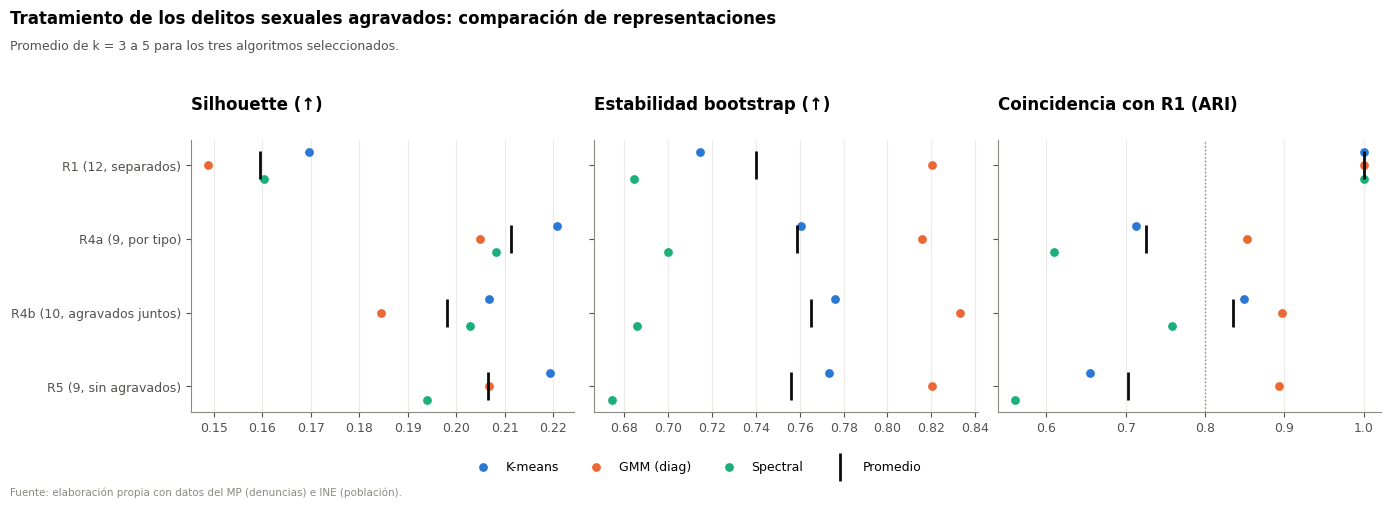

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
etiquetas = list(REPRESENTACIONES)
for ax, (col, titulo, linea) in zip(axes, [("silhouette", "Silhouette (↑)", None),
                                           ("estabilidad", "Estabilidad bootstrap (↑)", None),
                                           ("ARI_vs_R1", "Coincidencia con R1 (ARI)", 0.80)]):
    for j, alg in enumerate(SELECCIONADOS):
        d = comp[comp["algoritmo"] == alg].groupby("representación", sort=False)[col].mean()
        ax.scatter(d.values, np.arange(len(etiquetas)) + (j - 1) * 0.18, s=40,
                   color=PALETA_CATEGORICA[j], label=alg, zorder=3)
    media = comp.groupby("representación", sort=False)[col].mean()
    ax.scatter(media.values, range(len(etiquetas)), marker="|", s=400, color=COLOR["texto"],
               zorder=4, label="Promedio")
    if linea:
        ax.axvline(linea, color=COLOR["gris"], linestyle=":", linewidth=1)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(etiquetas)), etiquetas)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.03))
fig.suptitle("Tratamiento de los delitos sexuales agravados: comparación de representaciones",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.9, "Promedio de k = 3 a 5 para los tres algoritmos seleccionados.",
         fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.1, 1, 0.9))
guardar_figura(fig, "06_comparacion_representaciones", CARPETA_FIG)
plt.show()

### 5.3 Aplicación de la regla de decisión

In [11]:
candidatas = resumen_rep[resumen_rep["cumple regla"]]
if candidatas.empty:
    REPRESENTACION = "R1 (12, separados)"
else:
    conservan = candidatas[~candidatas.index.str.startswith("R5")]
    elegible = conservan if not conservan.empty else candidatas
    REPRESENTACION = elegible["ARI_vs_R1"].idxmax()
ARCHIVO_REPRESENTACION = REPRESENTACIONES[REPRESENTACION]
print(f"Representación elegida: {REPRESENTACION}  ->  {ARCHIVO_REPRESENTACION}")

Representación elegida: R4b (10, agravados juntos)  ->  R4b_agravados_agrupados


## 6. Confirmación: ¿cambia la selección de algoritmos con la representación elegida?

In [12]:
X_final = cargar(ARCHIVO_REPRESENTACION)
resultados_final = barrido(X_final, algoritmos=list(FAMILIA))
resultados_final.to_csv(RUTA_REPORTES / "05_barrido_algoritmos_final.csv", index=False, encoding="utf-8-sig")
ranking_final = puntuar(resultados_final)
mejor_final = ranking_final.reset_index().groupby("familia").first().sort_values("puntuacion")
display(mejor_final[["algoritmo", "puntuacion", "silhouette", "estabilidad", "balance"]].round(3))
SELECCIONADOS_FINAL = mejor_final["algoritmo"].head(3).tolist()
print("Selección con R1:              ", SELECCIONADOS)
print("Selección con la elegida:      ", SELECCIONADOS_FINAL)
print("¿Se mantiene la selección?     ", sorted(SELECCIONADOS) == sorted(SELECCIONADOS_FINAL))

,algoritmo,puntuacion,silhouette,estabilidad,balance
familia,,,,,
Particional,K-means,2.61,0.19,0.78,1.00
Probabilística,GMM (diag),2.83,0.17,0.83,1.00
Grafos,Spectral,3.50,0.19,0.69,1.00
Jerárquica,Ward,5.06,0.15,0.43,1.00


Selección con R1:               ['K-means', 'GMM (diag)', 'Spectral']
Selección con la elegida:       ['K-means', 'GMM (diag)', 'Spectral']
¿Se mantiene la selección?      True


## 7. Registro de decisiones

Se guarda un archivo con las decisiones para que el notebook 06 las use sin copiarlas a mano.

In [13]:
decisiones = {
    "representacion": ARCHIVO_REPRESENTACION,
    "algoritmos": SELECCIONADOS_FINAL,
    "algoritmos_descartados": {
        "DBSCAN / HDBSCAN": "Sin partición útil: un solo grupo o más del 69 % de ruido.",
        **{a: (f"Misma familia ({FAMILIA[a]}) que un algoritmo seleccionado, con menor puntuación."
               if FAMILIA[a] in {FAMILIA[s] for s in SELECCIONADOS_FINAL}
               else f"Familia {FAMILIA[a]} con menor puntuación (baja estabilidad).")
           for a in FAMILIA if a not in SELECCIONADOS_FINAL},
    },
    "rango_k_evaluacion": K_EVALUACION,
    "semilla": SEMILLA,
}
with open(RUTA_REPORTES / "05_decisiones.json", "w", encoding="utf-8") as f:
    json.dump(decisiones, f, ensure_ascii=False, indent=2)
print(json.dumps(decisiones, ensure_ascii=False, indent=2))

{
  "representacion": "R4b_agravados_agrupados",
  "algoritmos": [
    "K-means",
    "GMM (diag)",
    "Spectral"
  ],
  "algoritmos_descartados": {
    "DBSCAN / HDBSCAN": "Sin partición útil: un solo grupo o más del 69 % de ruido.",
    "K-medoids": "Misma familia (Particional) que un algoritmo seleccionado, con menor puntuación.",
    "Ward": "Familia Jerárquica con menor puntuación (baja estabilidad).",
    "BIRCH": "Familia Jerárquica con menor puntuación (baja estabilidad).",
    "GMM (tied)": "Misma familia (Probabilística) que un algoritmo seleccionado, con menor puntuación.",
    "GMM (full)": "Misma familia (Probabilística) que un algoritmo seleccionado, con menor puntuación."
  },
  "rango_k_evaluacion": [
    3,
    4,
    5,
    6
  ],
  "semilla": 42
}
